# Лабораторная работа № 2. Pandas и корреляционный анализ

**Цель:** освоить загрузку и анализ табличных данных средствами Pandas, а также вычисление и интерпретацию коэффициента корреляции Пирсона.

В ноутбуке исследуются два набора данных: пассажиры «Титаника» и показатели мозга. Реализации функций, соответствующих контрактам задания, находятся в `pandas_tasks.py` и `correlation_tasks.py`.

## 1. Анализ данных Titanic

Загрузим набор данных, проверим его структуру и рассчитаем количество пропусков, число пассажиров старше 30 лет, средний возраст и долю выживших по классам, а также пять максимальных тарифов.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pandas_tasks import analyze_titanic
from correlation_tasks import analyze_brain_correlations
from grader_contracts.pandas_tasks import TitanicInput
from grader_contracts.correlation_tasks import BrainDataInput

sns.set_theme()
data_dir = Path('.')
titanic = pd.read_csv(data_dir / 'titanic.csv')
print('Размер таблицы:', titanic.shape)
display(titanic.head())
print('Типы столбцов:')
print(titanic.dtypes)

Размер таблицы: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Типы столбцов:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [2]:
titanic_result = analyze_titanic(TitanicInput(str(data_dir / 'titanic.csv')))
print(titanic_result)

TitanicSummary(row_count=891, missing_by_column={'PassengerId': 0, 'Survived': 0, 'Pclass': 0, 'Name': 0, 'Sex': 0, 'Age': 177, 'SibSp': 0, 'Parch': 0, 'Ticket': 0, 'Fare': 0, 'Cabin': 687, 'Embarked': 2}, adults_over_30_count=305, mean_age_by_pclass={1: 38.233440860215055, 2: 29.87763005780347, 3: 25.14061971830986}, survival_rate_by_pclass={1: 0.6296296296296297, 2: 0.47282608695652173, 3: 0.24236252545824846}, highest_fares=[512.3292, 512.3292, 512.3292, 263.0, 263.0])


### Визуализация Titanic

Сравним средний возраст и долю выживших между пассажирами разных классов.

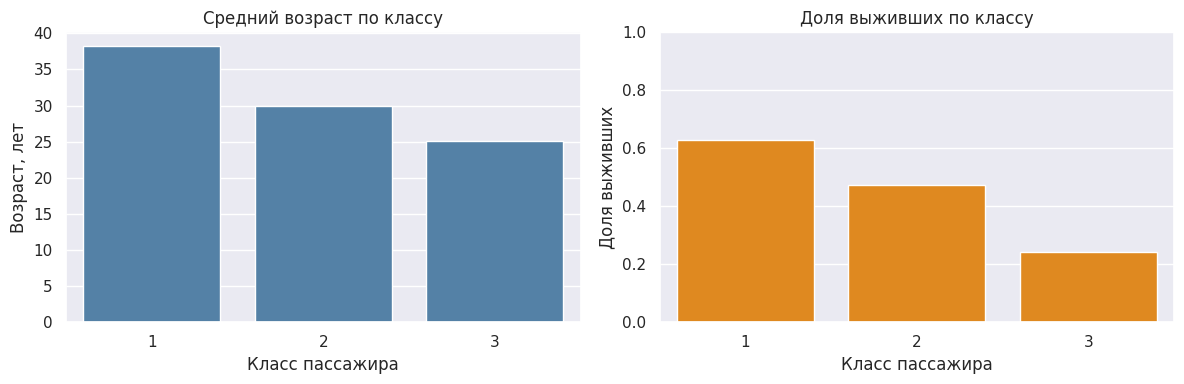

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=titanic, x='Pclass', y='Age', errorbar=None, color='steelblue', ax=axes[0])
axes[0].set_title('Средний возраст по классу')
axes[0].set_xlabel('Класс пассажира')
axes[0].set_ylabel('Возраст, лет')

sns.barplot(data=titanic, x='Pclass', y='Survived', errorbar=None, color='darkorange', ax=axes[1])
axes[1].set_title('Доля выживших по классу')
axes[1].set_xlabel('Класс пассажира')
axes[1].set_ylabel('Доля выживших')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Вывод по Titanic.** В наборе 891 пассажир. Возраст отсутствует у 177 записей, поэтому пропуски не заменяются нулём при расчёте среднего. Число пассажиров старше 30 лет составляет 305. Средний возраст уменьшается от первого класса к третьему (примерно 38,23; 29,88 и 25,14 года). Доля выживших также выше в первом классе (около 0,630), чем во втором (0,473) и третьем (0,242).

## 2. Корреляционный анализ показателей мозга

Загрузим `brainsize.txt` с табуляцией в качестве разделителя. Значения `NA` будут распознаны как пропуски. Для мужчин и женщин отдельно вычислим корреляции Пирсона пяти признаков с `MRI_Count`.

In [4]:
brain = pd.read_csv(data_dir / 'brainsize.txt', sep='\t', na_values=['NA'])
print('Размер таблицы:', brain.shape)
display(brain.head())
print('Пропуски по столбцам:')
print(brain.isna().sum())

brain_result = analyze_brain_correlations(BrainDataInput(str(data_dir / 'brainsize.txt')))
print(brain_result)

Размер таблицы: (40, 7)


,Gender,FSIQ,VIQ,PIQ,Weight,Height,MRI_Count
0,Female,133,132,124,118.0,64.5,816932
1,Male,140,150,124,NaN,72.5,1001121
2,Male,139,123,150,143.0,73.3,1038437
3,Male,133,129,128,172.0,68.8,965353
4,Female,137,132,134,147.0,65.0,951545


Пропуски по столбцам:
Gender       0
FSIQ         0
VIQ          0
PIQ          0
Weight       2
Height       1
MRI_Count    0
dtype: int64
BrainCorrelationSummary(men_count=20, women_count=20, women_mri_correlation={'FSIQ': 0.32569670049637084, 'VIQ': 0.25493285296147683, 'PIQ': 0.3961571668684768, 'Weight': 0.4462713526616431, 'Height': 0.17454104728809916}, men_mri_correlation={'FSIQ': 0.49836911041719284, 'VIQ': 0.4131049601428289, 'PIQ': 0.5682370032144162, 'Weight': -0.07687464371333148, 'Height': 0.30154304017705763}, strongest_mri_feature='PIQ')


### Диаграммы рассеяния

Построим диаграммы зависимости каждого признака от `MRI_Count`. Цвет точек показывает пол наблюдаемого.

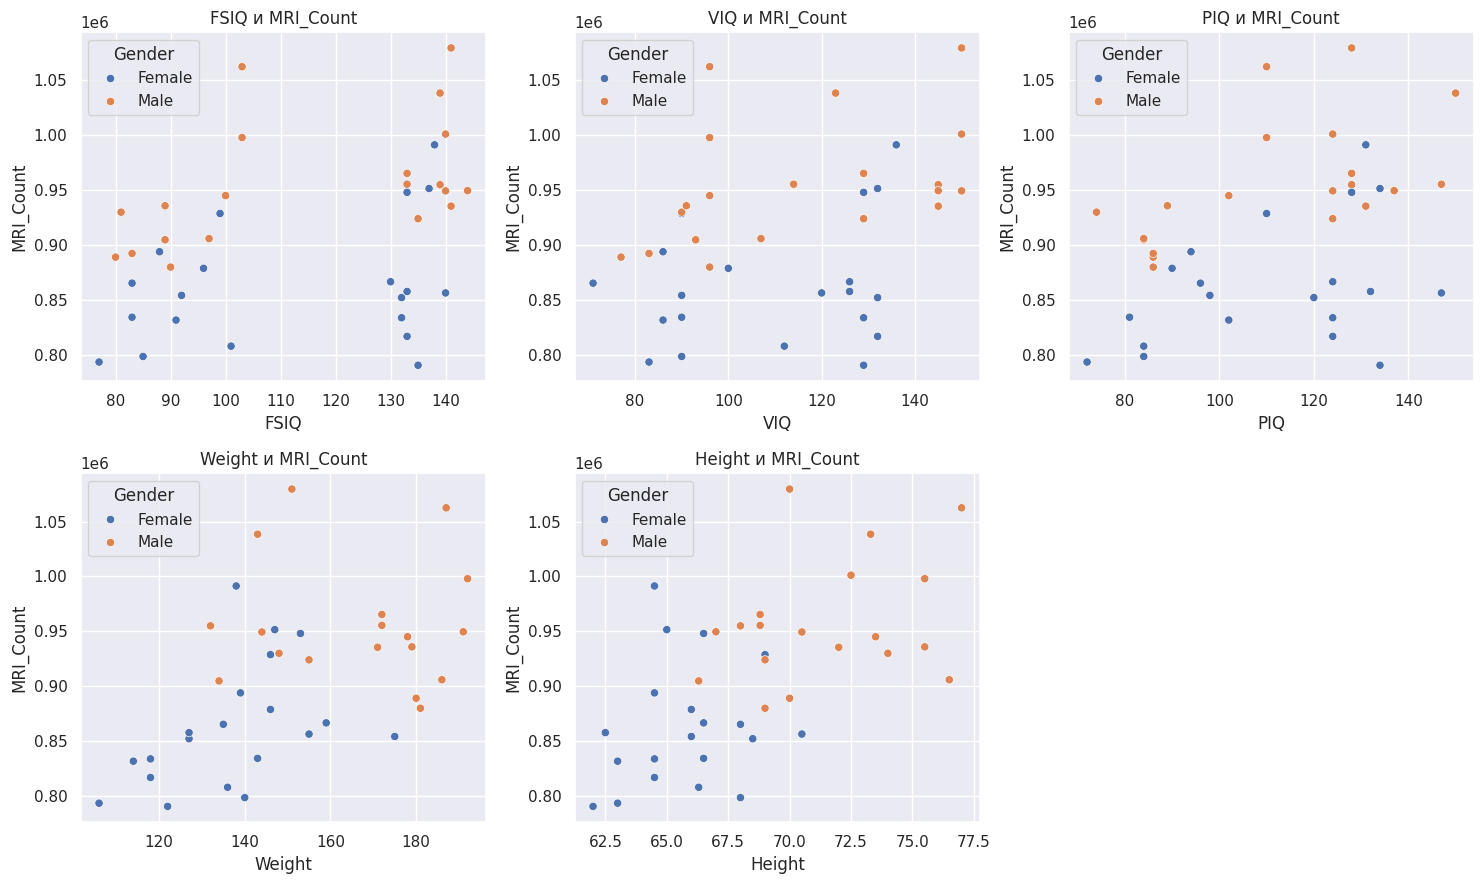

In [5]:
features = ['FSIQ', 'VIQ', 'PIQ', 'Weight', 'Height']
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for feature, ax in zip(features, axes.flat):
    sns.scatterplot(data=brain, x=feature, y='MRI_Count', hue='Gender', ax=ax)
    ax.set_title(f'{feature} и MRI_Count')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

### Тепловые карты корреляций

Тепловые карты показывают корреляции Пирсона между всеми числовыми признаками отдельно для каждой группы. Пропуски учитываются попарно: для каждой пары признаков используются доступные совместные наблюдения.

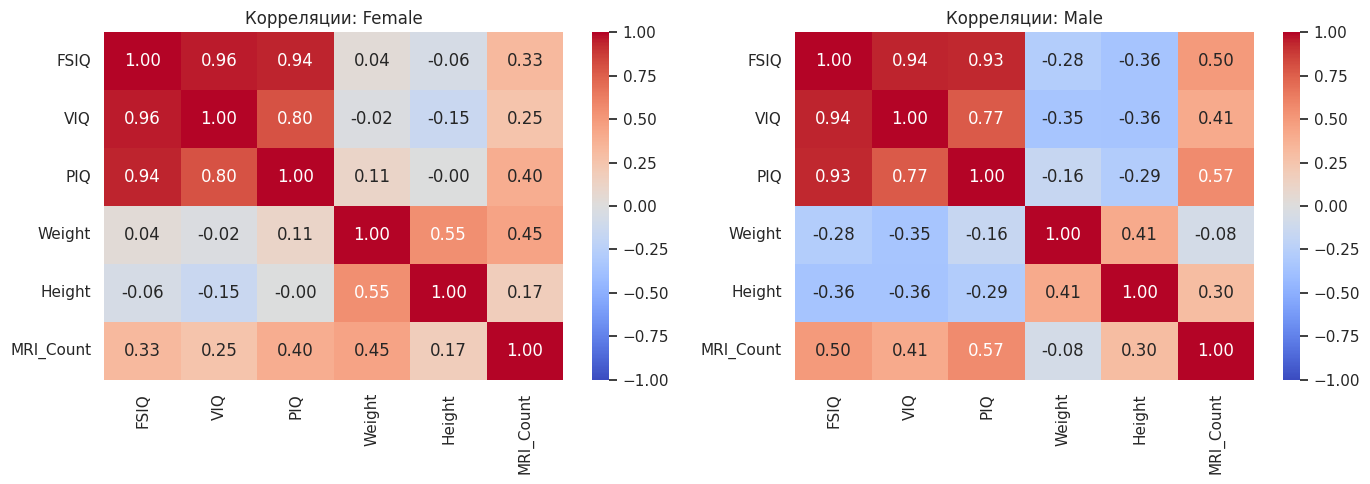

In [6]:
numeric_features = features + ['MRI_Count']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for gender, ax in zip(['Female', 'Male'], axes):
    group = brain.loc[brain['Gender'] == gender, numeric_features]
    corr = group.corr(method='pearson')
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
                vmin=-1, vmax=1, ax=ax)
    ax.set_title(f'Корреляции: {gender}')
plt.tight_layout()
plt.show()

**Вывод по корреляционному анализу.** В выборке 20 мужчин и 20 женщин. Наибольшая по модулю корреляция с `MRI_Count` среди рассчитанных групповых коэффициентов наблюдается у `PIQ` (у мужчин примерно 0,568, у женщин примерно 0,396). Это положительная корреляционная связь: в рамках данной выборки более высокие значения `PIQ` связаны с большим `MRI_Count`. Корреляция сама по себе не доказывает причинно-следственную связь. Отрицательная или слабая корреляция не означает отсутствия любых возможных зависимостей, а отражает только линейную связь в этой выборке.

## Общий вывод

В ходе лабораторной работы с помощью Pandas выполнены загрузка и первичный анализ двух наборов данных. Для Titanic рассчитаны пропуски, возрастные и классовые показатели, а также максимальные тарифы. Для набора `brainsize.txt` рассчитаны корреляции Пирсона по группам мужчин и женщин, построены диаграммы рассеяния и тепловые карты корреляций. Наибольший модуль групповой корреляции с `MRI_Count` получен для признака `PIQ`.